# Población nacida en el extranjero y empleo de los nacidos en el país

In [ ]:
# Parámetros de la gráfica
SLUG = "empleo"  # carpeta en research/temas/
GRAFICA_ID = "poblacion-extranjera-empleo-nativos"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Población nacida en el extranjero y empleo de los nacidos en el país"  # `titulo` de la gráfica en config.json
DESDE = 1976  # primer año candidato (METODOLOGIA §2.3)
UNIVERSO = "ue27"  # ocde | ue27: todos sus países con dato en los dos ejes (METODOLOGIA §2.6)
EJE_X = {"titulo": "Población nacida en el extranjero", "unidad": "% de la población de 20 a 64 años"}
EJE_Y = {"titulo": "Tasa de empleo de los nacidos en el país", "unidad": "% de la población de 20 a 64 años nacida en el país"}
ANIOS = None  # (desde, hasta) si el config fija una ventana; None = último año común de cada país
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

Cada punto es un país de la UE-27 con dato en los dos ejes.

- **Eje horizontal:** el **porcentaje de la población de 20 a 64 años nacida en el extranjero**.
- **Eje vertical:** la **tasa de empleo de las personas de 20 a 64 años nacidas en el país** que se estudia.

**Para qué sirve.** Es el argumento de quienes sostienen que la inmigración complementa el empleo de los nacidos en el país en lugar de quitárselo; su pareja es `poblacion-extranjera-empleo-nativos-estudios-bajos`, con los nacidos en el país con estudios básicos, que son quienes más a menudo trabajan en las mismas ocupaciones que los inmigrantes. **La relación entre dos indicadores no muestra que uno cause el otro**: la inmigración se dirige a los países y años con más demanda de trabajo. No se dibuja línea de tendencia ni se calcula la correlación.

**Limitaciones.**
- Se usa el país de nacimiento, no la nacionalidad.
- La tasa de empleo depende de muchos factores además de la inmigración: el ciclo económico, la estructura de edades y de estudios, y las instituciones del mercado de trabajo.
- Universo: UE-27, porque los dos ejes solo existen en Eurostat. Cada punto usa el último año en que el país tiene dato en los dos ejes.

## 2. Descarga

- **Eje x: Eurostat `migr_pop3ctb`**: población a 1 de enero por país de nacimiento (`c_birth=FOR` y `TOTAL`), ambos sexos, en número de personas, por grupos quinquenales de edad de `Y20-24` a `Y60-64`, que se suman.
- **Eje y: Eurostat `lfsa_ergacob`**: tasa de empleo (`PC`) de 20 a 64 años de la población nacida en el país (`c_birth=NAT`), ambos sexos.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.paises import paises_de
from lib.writer import construir_dispersion_data, write_dispersion_data

PAISES = paises_de(UNIVERSO)

from lib import eurostat
from lib.paises import CODIGOS_EUROSTAT
from lib.tipos import FuenteMeta

GEOS = {**{CODIGOS_EUROSTAT[c]: c for c in PAISES}, "EU27_2020": "EU27_2020"}  # código Eurostat → clave de la serie
GRUPOS = ["Y20-24", "Y25-29", "Y30-34", "Y35-39", "Y40-44", "Y45-49", "Y50-54", "Y55-59", "Y60-64"]


def poblacion(c_birth):
    """Población de 20 a 64 años a 1 de enero (suma de los grupos quinquenales), solo los años con todos los grupos."""
    partes = []
    for g in GRUPOS:
        d, _ = eurostat.get("migr_pop3ctb", {"c_birth": c_birth, "age": g, "sex": "T", "unit": "NR"}, geos=GEOS, desde=DESDE)
        partes.append(d.set_index(["serie", "periodo"])["valor"].rename(g))
    return pd.concat(partes, axis=1).dropna().sum(axis=1)


extranjero, total = poblacion("FOR"), poblacion("TOTAL")
y, fuentes_y = eurostat.get("lfsa_ergacob", {"c_birth": "NAT", "age": "Y20-64", "sex": "T", "unit": "PC"}, geos=GEOS, desde=DESDE)
print("Países con población:", extranjero.index.get_level_values(0).nunique(), "· con tasa de empleo:", y["serie"].nunique())

Países con población: 28 · con tasa de empleo: 28


## 3. Transformación

1. **Eje x:** población nacida en el extranjero entre la población total, de 20 a 64 años, por 100, en los años en que están todos los grupos de edad.
2. **Eje y:** se usa tal como lo publica Eurostat.
3. **Punto de la UE-27:** Eurostat publica el agregado (`EU27_2020`) en los dos ejes; el escritor lo añade si coincide algún año.

In [ ]:
def es(v, d=1):
    return estilos.formato_es(v, d)


serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"].dropna()  # noqa: E731


def comparar(a, b):
    """Años comunes de dos series y diferencia absoluta entre ellas, en puntos."""
    comunes = sorted(set(a.index) & set(b.index))
    return comunes, (a[comunes] - b[comunes]).abs()


def nota_comparacion(texto, a, b, d=2):
    comunes, dif = comparar(a, b)
    return (f"{texto}: en los {len(comunes)} años comunes ({comunes[0]}-{comunes[-1]}), la diferencia máxima es de "
            f"{es(dif.max(), d)} puntos, en {int(dif.idxmax())}.")

x = (extranjero / total * 100).dropna().rename("valor").reset_index()
assert x["valor"].between(0, 100).all(), "porcentaje fuera de rango"
HOY = fuentes_y[0].fecha_consulta
URL_POB = eurostat.URL_DATABROWSER.format(dataset="migr_pop3ctb")
fuentes = [
    FuenteMeta("eje_x", eurostat.ORGANISMO, "migr_pop3ctb (sex=T, unit=NR, de Y20-24 a Y60-64): c_birth=FOR entre c_birth=TOTAL", URL_POB, HOY),
    FuenteMeta("eje_y", eurostat.ORGANISMO, "lfsa_ergacob (c_birth=NAT, sex=T, age=Y20-64, unit=PC)", fuentes_y[0].url, HOY),
]
NOTAS = [
    "Población nacida en el extranjero: Eurostat (migr_pop3ctb), población a 1 de enero de 20 a 64 años nacida en el "
    "extranjero (c_birth=FOR) entre la población total de esa edad, suma de los grupos quinquenales de 20 a 64 años; "
    "solo los años con todos los grupos publicados. Es la población a 1 de enero; la tasa de empleo es la media del año.",
    "La inmigración se dirige a los países y los años con más demanda de trabajo, así que la relación entre los dos "
    "indicadores no muestra el efecto de la inmigración sobre el empleo; la evidencia causal se resume en la del enfoque "
    "vias_inmigracion de seguridad social.",
    "Tasa de empleo: Eurostat (lfsa_ergacob), ocupados de 20 a 64 años nacidos en el país en % de la población de esa "
    "edad nacida en el país, encuesta de población activa.",
    "Media UE-27: los agregados de composición actual (EU27_2020) que publica Eurostat en los dos ejes.",
]
for n in NOTAS:
    print("-", n)

- Población nacida en el extranjero: Eurostat (migr_pop3ctb), población a 1 de enero de 20 a 64 años nacida en el extranjero (c_birth=FOR) entre la población total de esa edad, suma de los grupos quinquenales de 20 a 64 años; solo los años con todos los grupos publicados. Es la población a 1 de enero; la tasa de empleo es la media del año.
- La inmigración se dirige a los países y los años con más demanda de trabajo, así que la relación entre los dos indicadores no muestra el efecto de la inmigración sobre el empleo; la evidencia causal se resume en la del enfoque vias_inmigracion de seguridad social.
- Tasa de empleo: Eurostat (lfsa_ergacob), ocupados de 20 a 64 años nacidos en el país en % de la población de esa edad nacida en el país, encuesta de población activa.
- Media UE-27: los agregados de composición actual (EU27_2020) que publica Eurostat en los dos ejes.


## 4. Visualización

Un punto por país, sin línea de tendencia ni correlación (METODOLOGIA §2.6).

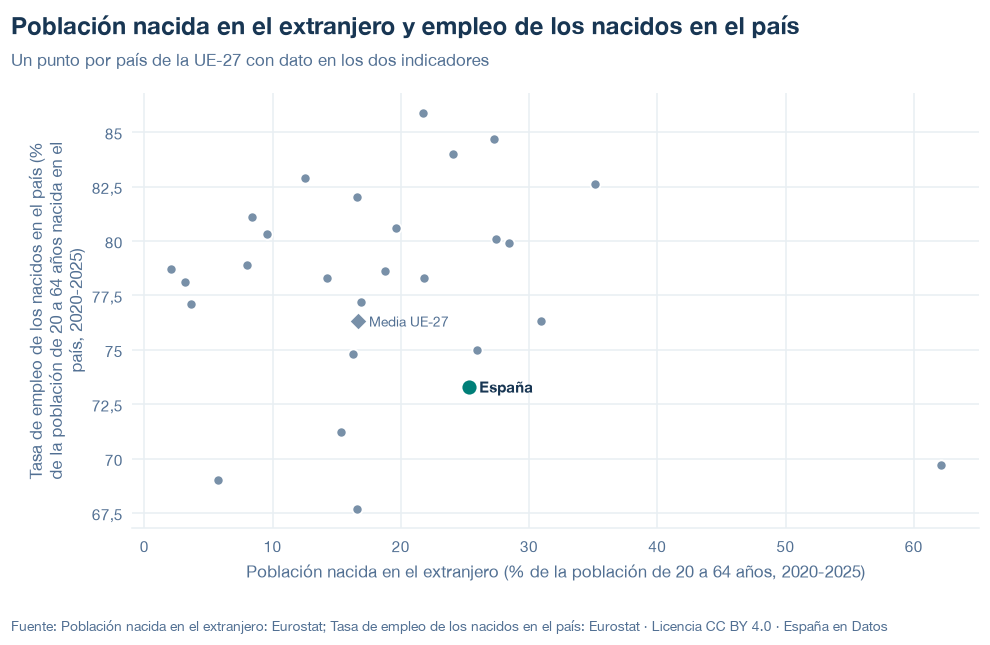

   codigo  anio         x    y
      AUT  2025 28.428245 79.9
      BEL  2025 25.918543 75.0
      BGR  2025  3.663096 77.1
      CYP  2025 35.108518 82.6
      CZE  2025 12.522280 82.9
      DEU  2025 24.095015 84.0
      DNK  2025 19.652846 80.6
      ESP  2025 25.284186 73.3
      EST  2025 16.553015 82.0
      FIN  2025 14.270356 78.3
      FRA  2025 16.912824 77.2
      GRC  2025 15.316604 71.2
      HRV  2025 16.304920 74.8
      HUN  2025  8.390995 81.1
      IRL  2025 27.391257 80.1
      ITA  2025 16.554659 67.7
      LTU  2025  9.557338 80.3
      LUX  2025 62.086624 69.7
      LVA  2025  7.980433 78.9
      MLT  2020 30.921930 76.3
      NLD  2025 21.755549 85.9
      POL  2025  2.042761 78.7
      PRT  2024 21.797002 78.3
      ROU  2025  5.732898 69.0
      SVK  2025  3.151303 78.1
      SVN  2025 18.734520 78.6
      SWE  2025 27.253687 84.7
EU27_2020  2023 16.684120 76.3


In [ ]:
datos = construir_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
)
fig = estilos.figura(datos, titulo=TITULO)
estilos.mostrar(fig)
print(pd.DataFrame(datos["puntos"]).to_string(index=False))

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web (`codigo;pais;anio;eje_x;eje_y`).

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/poblacion-extranjera-empleo-nativos.json y data/poblacion-extranjera-empleo-nativos.csv


## 6. Fuentes, notas y licencia

- Eurostat, `migr_pop3ctb` (`c_birth=FOR` y `TOTAL`, `sex=T`, `unit=NR`, grupos de `Y20-24` a `Y60-64`).
- Eurostat, `lfsa_ergacob` (`c_birth=NAT`, `sex=T`, `age=Y20-64`, `unit=PC`).

La fecha de consulta de cada eje está en `fuentes` del JSON; las notas incluyen los países sin dato y la advertencia de que la relación no muestra causa.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.